# Finance Data Analysis

End-to-end EDA, cleaning, standardization, feature engineering, and visualization on a real-world messy finance transactions dataset.

## 1. Setup and Finance Data Generation

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import random
import string

In [2]:
# List of dataset
finance_dataurl_1 = 'https://raw.githubusercontent.com/vinothsivaperumal/eda/refs/heads/main/finance_dirty_data_1.csv'

#df_finance_1 = pd.read_csv(finance_dataurl_1)

## 1. Load the Dataset

### Question 1
Load the finance CSV file and display the first 10 rows.

In [3]:
dataset_url = "https://raw.githubusercontent.com/vinothsivaperumal/eda/refs/heads/main/finance_dirty_data_1.csv"

df = pd.read_csv(dataset_url)
df.head(10)

,Transaction_ID,Transaction_Date,Customer_Name,City,Account_Type,Transaction_Type,Channel,Status,Amount,Fee,Balance,Credit_Score,Customer_Age,Risk_Score,Email
0,5001,2025-11-29,Betty Arnold,Seattle,CHECKING,Deposit,Branch,PENDING,399.54,0.0,12622.15,591.0,68,0.19,NaN
1,5002,2025-04-29,Sabrina Williams,DALLAS,Loan,Withdrawal,ATM,PENDING,6751.91,0.0,40566.81,523.0,69,0.78,pherrera@example.org
2,5003,2025-06-06,Joseph Brown,Chicago,Credit,Deposit,Mobile,Pending,10952.73,5.0,NaN,713.0,26,0.57,lopezveronica@example.org
3,5004,2026-02-24,Lori Powers,Atlanta,Savings,Transfer,Online,Failed,4187.65,10.0,41788.47,603.0,44,0.40,michael84@example.com
4,5005,2025-11-15,Jason Wright,Atlanta,CHECKING,payment,Online,completed,8365.32,10.0,16552.00,548.0,35,0.80,anthonycasey@example.org
5,5006,2026-01-04,Brittney Martin,New York,Checking,Payment,Branch,Pending,2115.96,10.0,28287.72,654.0,68,0.60,benjaminmurphy@example.org
6,5007,2025-05-17,Cynthia Green,Chicago,CHECKING,Transfer,Mobile,Failed,8956.23,2.5,19390.15,759.0,54,0.31,gonzalezcharles@example.org
7,5008,2025-08-22,CHRISTINA ANDERSON,Dallas,Loan,Withdrawal,mobile,PENDING,6819.51,10.0,43854.72,654.0,53,0.75,shannonroberts@example.net
8,5009,03/24/2025,Jennifer Rodgers,Dallas,Savings,Fee,Branch,completed,4879.24,0.0,6037.45,705.0,40,0.30,lgiles@example.net
9,5010,2025-11-07,Kelly Martinez,Dallas,savings,Withdrawal,Branch,Completed,3994.22,15.0,30526.40,628.0,55,0.74,garciakyle@example.com


## 2. Data Discovery

### Question 2
Find the number of rows and columns in the dataset.

In [4]:
df.count()

Transaction_ID      5002
Transaction_Date    5002
Customer_Name       5002
City                5002
Account_Type        5002
Transaction_Type    5002
Channel             5002
Status              5002
Amount              4609
Fee                 5002
Balance             4742
Credit_Score        4818
Customer_Age        5002
Risk_Score          5002
Email               4688
dtype: int64

### Question 3
Display the column names and data types.

In [5]:
df.columns.tolist()

['Transaction_ID',
 'Transaction_Date',
 'Customer_Name',
 'City',
 'Account_Type',
 'Transaction_Type',
 'Channel',
 'Status',
 'Amount',
 'Fee',
 'Balance',
 'Credit_Score',
 'Customer_Age',
 'Risk_Score',
 'Email']

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5002 entries, 0 to 5001
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    5002 non-null   int64  
 1   Transaction_Date  5002 non-null   str    
 2   Customer_Name     5002 non-null   str    
 3   City              5002 non-null   str    
 4   Account_Type      5002 non-null   str    
 5   Transaction_Type  5002 non-null   str    
 6   Channel           5002 non-null   str    
 7   Status            5002 non-null   str    
 8   Amount            4609 non-null   float64
 9   Fee               5002 non-null   float64
 10  Balance           4742 non-null   float64
 11  Credit_Score      4818 non-null   float64
 12  Customer_Age      5002 non-null   int64  
 13  Risk_Score        5002 non-null   float64
 14  Email             4688 non-null   str    
dtypes: float64(5), int64(2), str(8)
memory usage: 586.3 KB


### Question 4
Show summary statistics for numerical columns.

In [7]:
df.describe()

,Transaction_ID,Amount,Fee,Balance,Credit_Score,Customer_Age,Risk_Score
count,5002.000000,4609.000000,5002.000000,4742.000000,4818.000000,5002.000000,5002.000000
mean,7498.513195,7575.946314,4.617653,25577.430970,685.030511,45.422031,0.526879
std,1444.074625,4366.448935,5.372544,14291.940697,94.936018,14.349691,0.246641
min,5001.000000,28.740000,0.000000,509.760000,520.000000,21.000000,0.100000
25%,6248.250000,3674.270000,0.000000,13073.772500,603.000000,33.000000,0.320000
50%,7498.500000,7673.880000,2.500000,25660.550000,686.000000,46.000000,0.530000
75%,8748.750000,11460.890000,10.000000,37956.125000,766.000000,58.000000,0.740000
max,9999.000000,14997.420000,15.000000,49987.310000,850.000000,70.000000,0.950000


### Question 5
Count missing values in each column.

In [8]:
df.isnull().sum()

Transaction_ID        0
Transaction_Date      0
Customer_Name         0
City                  0
Account_Type          0
Transaction_Type      0
Channel               0
Status                0
Amount              393
Fee                   0
Balance             260
Credit_Score        184
Customer_Age          0
Risk_Score            0
Email               314
dtype: int64

### Question 6
Find unique values in Account_Type, Transaction_Type, Channel, and Status.

In [9]:
df.head(3)

,Transaction_ID,Transaction_Date,Customer_Name,City,Account_Type,Transaction_Type,Channel,Status,Amount,Fee,Balance,Credit_Score,Customer_Age,Risk_Score,Email
0,5001,2025-11-29,Betty Arnold,Seattle,CHECKING,Deposit,Branch,PENDING,399.54,0.0,12622.15,591.0,68,0.19,NaN
1,5002,2025-04-29,Sabrina Williams,DALLAS,Loan,Withdrawal,ATM,PENDING,6751.91,0.0,40566.81,523.0,69,0.78,pherrera@example.org
2,5003,2025-06-06,Joseph Brown,Chicago,Credit,Deposit,Mobile,Pending,10952.73,5.0,NaN,713.0,26,0.57,lopezveronica@example.org


In [10]:
print("Account_Type_Unique: ", df["Account_Type"].unique())
print("Transaction_Type_Unique: ", df["Transaction_Type"].unique())
print("Chanel_Unique: ", df["Channel"].unique())
print("Status_Unique: ", df["Status"].unique())

Account_Type_Unique:  <StringArray>
['CHECKING ', 'Loan', 'Credit', 'Savings', 'Checking', ' savings']
Length: 6, dtype: str
Transaction_Type_Unique:  <StringArray>
['Deposit', 'Withdrawal', 'Transfer', 'payment ', 'Payment', 'Fee']
Length: 6, dtype: str
Chanel_Unique:  <StringArray>
['Branch', 'ATM', 'Mobile', 'Online', 'mobile ', 'BRANCH']
Length: 6, dtype: str
Status_Unique:  <StringArray>
['PENDING', 'Pending', 'Failed', 'completed ', 'Completed']
Length: 5, dtype: str


In [11]:
for col in ["Account_Type", "Transaction_Type", "Channel", "Status"]:
    print(f"\n{col}:")
    print(df[col].unique())


Account_Type:
<StringArray>
['CHECKING ', 'Loan', 'Credit', 'Savings', 'Checking', ' savings']
Length: 6, dtype: str

Transaction_Type:
<StringArray>
['Deposit', 'Withdrawal', 'Transfer', 'payment ', 'Payment', 'Fee']
Length: 6, dtype: str

Channel:
<StringArray>
['Branch', 'ATM', 'Mobile', 'Online', 'mobile ', 'BRANCH']
Length: 6, dtype: str

Status:
<StringArray>
['PENDING', 'Pending', 'Failed', 'completed ', 'Completed']
Length: 5, dtype: str


### Question 7
Inspect distinct values in City, Account_Type, Transaction_Type, and Status to identify inconsistencies.

In [12]:
for col in ["City", "Account_Type", "Transaction_Type", "Status"]:
    print(f"\n{col}:")
    clean = df[col].str.strip().str.lower()
    print(clean.unique())


City:
<StringArray>
['seattle', 'dallas', 'chicago', 'atlanta', 'new york']
Length: 5, dtype: str

Account_Type:
<StringArray>
['checking', 'loan', 'credit', 'savings']
Length: 4, dtype: str

Transaction_Type:
<StringArray>
['deposit', 'withdrawal', 'transfer', 'payment', 'fee']
Length: 5, dtype: str

Status:
<StringArray>
['pending', 'failed', 'completed']
Length: 3, dtype: str


### Question 8
Check whether duplicate rows exist.

In [13]:
df[df.duplicated()]

,Transaction_ID,Transaction_Date,Customer_Name,City,Account_Type,Transaction_Type,Channel,Status,Amount,Fee,Balance,Credit_Score,Customer_Age,Risk_Score,Email
4999,5011,09/18/2025,MATTHEW ROBINSON,Seattle,Credit,Deposit,Branch,PENDING,8834.92,0.0,29627.79,523.0,25,0.70,nmorgan@example.org
5000,5021,2025-04-20,Amber Leblanc,Dallas,Checking,payment,BRANCH,Failed,3761.71,0.0,18007.09,806.0,47,0.93,osbornejennifer@example.org
5001,5031,2025-03-24,Anna Norris,DALLAS,Checking,Withdrawal,mobile,completed,5760.95,0.0,35467.75,552.0,47,0.45,bcarlson@example.net


## 3. Data Cleaning

### Question 9
Create a working copy of the dataset before cleaning.

In [14]:
df_copied = df.copy()

### Question 10
Remove duplicate rows.

In [15]:
df_clean = df_copied.drop_duplicates()

print("After:", df_clean.shape)

After: (4999, 15)


### Question 11
Fill missing Amount with median Amount.

In [16]:
df_clean.loc[:, "Amount"] = df_clean["Amount"].fillna(df_clean["Amount"].median())

df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 4999 entries, 0 to 4998
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    4999 non-null   int64  
 1   Transaction_Date  4999 non-null   str    
 2   Customer_Name     4999 non-null   str    
 3   City              4999 non-null   str    
 4   Account_Type      4999 non-null   str    
 5   Transaction_Type  4999 non-null   str    
 6   Channel           4999 non-null   str    
 7   Status            4999 non-null   str    
 8   Amount            4999 non-null   float64
 9   Fee               4999 non-null   float64
 10  Balance           4739 non-null   float64
 11  Credit_Score      4815 non-null   float64
 12  Customer_Age      4999 non-null   int64  
 13  Risk_Score        4999 non-null   float64
 14  Email             4685 non-null   str    
dtypes: float64(5), int64(2), str(8)
memory usage: 585.9 KB


### Question 12
Fill missing Balance with median Balance.

In [17]:
df_clean.loc[:, "Balance"] = df_clean["Balance"].fillna(df_clean["Balance"].median())

df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 4999 entries, 0 to 4998
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    4999 non-null   int64  
 1   Transaction_Date  4999 non-null   str    
 2   Customer_Name     4999 non-null   str    
 3   City              4999 non-null   str    
 4   Account_Type      4999 non-null   str    
 5   Transaction_Type  4999 non-null   str    
 6   Channel           4999 non-null   str    
 7   Status            4999 non-null   str    
 8   Amount            4999 non-null   float64
 9   Fee               4999 non-null   float64
 10  Balance           4999 non-null   float64
 11  Credit_Score      4815 non-null   float64
 12  Customer_Age      4999 non-null   int64  
 13  Risk_Score        4999 non-null   float64
 14  Email             4685 non-null   str    
dtypes: float64(5), int64(2), str(8)
memory usage: 585.9 KB


### Question 13
Fill missing Credit_Score with median Credit_Score.

In [18]:
df_clean.loc[:, "Credit_Score"] = df_clean["Credit_Score"].fillna(df_clean["Credit_Score"].median())

df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 4999 entries, 0 to 4998
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    4999 non-null   int64  
 1   Transaction_Date  4999 non-null   str    
 2   Customer_Name     4999 non-null   str    
 3   City              4999 non-null   str    
 4   Account_Type      4999 non-null   str    
 5   Transaction_Type  4999 non-null   str    
 6   Channel           4999 non-null   str    
 7   Status            4999 non-null   str    
 8   Amount            4999 non-null   float64
 9   Fee               4999 non-null   float64
 10  Balance           4999 non-null   float64
 11  Credit_Score      4999 non-null   float64
 12  Customer_Age      4999 non-null   int64  
 13  Risk_Score        4999 non-null   float64
 14  Email             4685 non-null   str    
dtypes: float64(5), int64(2), str(8)
memory usage: 585.9 KB


### Question 14
Replace missing Email values with `unknown@email.com`.

In [19]:
df_clean.loc[:, "Email"] = df_clean["Email"].fillna("unknown@email.com")

df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 4999 entries, 0 to 4998
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    4999 non-null   int64  
 1   Transaction_Date  4999 non-null   str    
 2   Customer_Name     4999 non-null   str    
 3   City              4999 non-null   str    
 4   Account_Type      4999 non-null   str    
 5   Transaction_Type  4999 non-null   str    
 6   Channel           4999 non-null   str    
 7   Status            4999 non-null   str    
 8   Amount            4999 non-null   float64
 9   Fee               4999 non-null   float64
 10  Balance           4999 non-null   float64
 11  Credit_Score      4999 non-null   float64
 12  Customer_Age      4999 non-null   int64  
 13  Risk_Score        4999 non-null   float64
 14  Email             4999 non-null   str    
dtypes: float64(5), int64(2), str(8)
memory usage: 585.9 KB


### Question 15
Convert Transaction_Date to datetime.

In [20]:
df_clean["Transaction_Date"] = pd.to_datetime(
    df_clean["Transaction_Date"], errors="coerce"
)

df_clean

,Transaction_ID,Transaction_Date,Customer_Name,City,Account_Type,Transaction_Type,Channel,Status,Amount,Fee,Balance,Credit_Score,Customer_Age,Risk_Score,Email
0,5001,2025-11-29,Betty Arnold,Seattle,CHECKING,Deposit,Branch,PENDING,399.54,0.0,12622.15,591.0,68,0.19,unknown@email.com
1,5002,2025-04-29,Sabrina Williams,DALLAS,Loan,Withdrawal,ATM,PENDING,6751.91,0.0,40566.81,523.0,69,0.78,pherrera@example.org
2,5003,2025-06-06,Joseph Brown,Chicago,Credit,Deposit,Mobile,Pending,10952.73,5.0,25655.99,713.0,26,0.57,lopezveronica@example.org
3,5004,2026-02-24,Lori Powers,Atlanta,Savings,Transfer,Online,Failed,4187.65,10.0,41788.47,603.0,44,0.40,michael84@example.com
4,5005,2025-11-15,Jason Wright,Atlanta,CHECKING,payment,Online,completed,8365.32,10.0,16552.00,548.0,35,0.80,anthonycasey@example.org
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4994,9995,2025-04-19,Larry Lopez,Seattle,Savings,Fee,mobile,completed,1507.23,0.0,12585.53,589.0,27,0.47,lrodriguez@example.com
4995,9996,NaT,Jason Harper,Atlanta,Credit,payment,Branch,Failed,4090.09,0.0,10071.95,636.0,38,0.17,brittneypace@example.com
4996,9997,2025-09-12,Brandon Hess,New York,Checking,Transfer,mobile,Completed,11955.51,0.0,42302.33,785.0,27,0.90,kim76@example.com
4997,9998,2026-03-16,Wesley Haas,Dallas,CHECKING,Fee,mobile,Failed,3656.97,0.0,32818.93,602.0,21,0.90,kimberly75@example.org


### Question 16
Check whether any dates failed during conversion.

In [21]:
df_clean["Transaction_Date"].isnull().sum()

np.int64(1261)

### Question 17
Fix invalid email values so they end with `.com`.

In [22]:
df_clean.loc[:, "Email"] = df_clean["Email"].apply(
    lambda x: x if str(x).endswith(".com") else str(x) + ".com"
)

df_clean.head()

,Transaction_ID,Transaction_Date,Customer_Name,City,Account_Type,Transaction_Type,Channel,Status,Amount,Fee,Balance,Credit_Score,Customer_Age,Risk_Score,Email
0,5001,2025-11-29,Betty Arnold,Seattle,CHECKING,Deposit,Branch,PENDING,399.54,0.0,12622.15,591.0,68,0.19,unknown@email.com
1,5002,2025-04-29,Sabrina Williams,DALLAS,Loan,Withdrawal,ATM,PENDING,6751.91,0.0,40566.81,523.0,69,0.78,pherrera@example.org.com
2,5003,2025-06-06,Joseph Brown,Chicago,Credit,Deposit,Mobile,Pending,10952.73,5.0,25655.99,713.0,26,0.57,lopezveronica@example.org.com
3,5004,2026-02-24,Lori Powers,Atlanta,Savings,Transfer,Online,Failed,4187.65,10.0,41788.47,603.0,44,0.40,michael84@example.com
4,5005,2025-11-15,Jason Wright,Atlanta,CHECKING,payment,Online,completed,8365.32,10.0,16552.00,548.0,35,0.80,anthonycasey@example.org.com


## 4. Data Standardization

### Question 18
Standardize all column names to lowercase with underscores.

In [23]:
df_clean.columns = df_clean.columns.str.lower().str.replace(" ", "_")

df_clean

,transaction_id,transaction_date,customer_name,city,account_type,transaction_type,channel,status,amount,fee,balance,credit_score,customer_age,risk_score,email
0,5001,2025-11-29,Betty Arnold,Seattle,CHECKING,Deposit,Branch,PENDING,399.54,0.0,12622.15,591.0,68,0.19,unknown@email.com
1,5002,2025-04-29,Sabrina Williams,DALLAS,Loan,Withdrawal,ATM,PENDING,6751.91,0.0,40566.81,523.0,69,0.78,pherrera@example.org.com
2,5003,2025-06-06,Joseph Brown,Chicago,Credit,Deposit,Mobile,Pending,10952.73,5.0,25655.99,713.0,26,0.57,lopezveronica@example.org.com
3,5004,2026-02-24,Lori Powers,Atlanta,Savings,Transfer,Online,Failed,4187.65,10.0,41788.47,603.0,44,0.40,michael84@example.com
4,5005,2025-11-15,Jason Wright,Atlanta,CHECKING,payment,Online,completed,8365.32,10.0,16552.00,548.0,35,0.80,anthonycasey@example.org.com
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4994,9995,2025-04-19,Larry Lopez,Seattle,Savings,Fee,mobile,completed,1507.23,0.0,12585.53,589.0,27,0.47,lrodriguez@example.com
4995,9996,NaT,Jason Harper,Atlanta,Credit,payment,Branch,Failed,4090.09,0.0,10071.95,636.0,38,0.17,brittneypace@example.com
4996,9997,2025-09-12,Brandon Hess,New York,Checking,Transfer,mobile,Completed,11955.51,0.0,42302.33,785.0,27,0.90,kim76@example.com
4997,9998,2026-03-16,Wesley Haas,Dallas,CHECKING,Fee,mobile,Failed,3656.97,0.0,32818.93,602.0,21,0.90,kimberly75@example.org.com


### Question 19
Standardize customer_name by removing extra spaces and converting to title case.

In [24]:
df_clean.loc[:, "customer_name"] = df_clean["customer_name"].str.strip().str.title()

df_clean

,transaction_id,transaction_date,customer_name,city,account_type,transaction_type,channel,status,amount,fee,balance,credit_score,customer_age,risk_score,email
0,5001,2025-11-29,Betty Arnold,Seattle,CHECKING,Deposit,Branch,PENDING,399.54,0.0,12622.15,591.0,68,0.19,unknown@email.com
1,5002,2025-04-29,Sabrina Williams,DALLAS,Loan,Withdrawal,ATM,PENDING,6751.91,0.0,40566.81,523.0,69,0.78,pherrera@example.org.com
2,5003,2025-06-06,Joseph Brown,Chicago,Credit,Deposit,Mobile,Pending,10952.73,5.0,25655.99,713.0,26,0.57,lopezveronica@example.org.com
3,5004,2026-02-24,Lori Powers,Atlanta,Savings,Transfer,Online,Failed,4187.65,10.0,41788.47,603.0,44,0.40,michael84@example.com
4,5005,2025-11-15,Jason Wright,Atlanta,CHECKING,payment,Online,completed,8365.32,10.0,16552.00,548.0,35,0.80,anthonycasey@example.org.com
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4994,9995,2025-04-19,Larry Lopez,Seattle,Savings,Fee,mobile,completed,1507.23,0.0,12585.53,589.0,27,0.47,lrodriguez@example.com
4995,9996,NaT,Jason Harper,Atlanta,Credit,payment,Branch,Failed,4090.09,0.0,10071.95,636.0,38,0.17,brittneypace@example.com
4996,9997,2025-09-12,Brandon Hess,New York,Checking,Transfer,mobile,Completed,11955.51,0.0,42302.33,785.0,27,0.90,kim76@example.com
4997,9998,2026-03-16,Wesley Haas,Dallas,CHECKING,Fee,mobile,Failed,3656.97,0.0,32818.93,602.0,21,0.90,kimberly75@example.org.com


### Question 20
Standardize city values.

In [25]:
df_clean.loc[:, "city"] = df_clean["city"].str.strip().str.title()

df_clean

,transaction_id,transaction_date,customer_name,city,account_type,transaction_type,channel,status,amount,fee,balance,credit_score,customer_age,risk_score,email
0,5001,2025-11-29,Betty Arnold,Seattle,CHECKING,Deposit,Branch,PENDING,399.54,0.0,12622.15,591.0,68,0.19,unknown@email.com
1,5002,2025-04-29,Sabrina Williams,Dallas,Loan,Withdrawal,ATM,PENDING,6751.91,0.0,40566.81,523.0,69,0.78,pherrera@example.org.com
2,5003,2025-06-06,Joseph Brown,Chicago,Credit,Deposit,Mobile,Pending,10952.73,5.0,25655.99,713.0,26,0.57,lopezveronica@example.org.com
3,5004,2026-02-24,Lori Powers,Atlanta,Savings,Transfer,Online,Failed,4187.65,10.0,41788.47,603.0,44,0.40,michael84@example.com
4,5005,2025-11-15,Jason Wright,Atlanta,CHECKING,payment,Online,completed,8365.32,10.0,16552.00,548.0,35,0.80,anthonycasey@example.org.com
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4994,9995,2025-04-19,Larry Lopez,Seattle,Savings,Fee,mobile,completed,1507.23,0.0,12585.53,589.0,27,0.47,lrodriguez@example.com
4995,9996,NaT,Jason Harper,Atlanta,Credit,payment,Branch,Failed,4090.09,0.0,10071.95,636.0,38,0.17,brittneypace@example.com
4996,9997,2025-09-12,Brandon Hess,New York,Checking,Transfer,mobile,Completed,11955.51,0.0,42302.33,785.0,27,0.90,kim76@example.com
4997,9998,2026-03-16,Wesley Haas,Dallas,CHECKING,Fee,mobile,Failed,3656.97,0.0,32818.93,602.0,21,0.90,kimberly75@example.org.com


### Question 21
Standardize account_type values.

In [26]:
df_clean.loc[:, "account_type"] = df_clean["account_type"].str.strip().str.title()

df_clean

,transaction_id,transaction_date,customer_name,city,account_type,transaction_type,channel,status,amount,fee,balance,credit_score,customer_age,risk_score,email
0,5001,2025-11-29,Betty Arnold,Seattle,Checking,Deposit,Branch,PENDING,399.54,0.0,12622.15,591.0,68,0.19,unknown@email.com
1,5002,2025-04-29,Sabrina Williams,Dallas,Loan,Withdrawal,ATM,PENDING,6751.91,0.0,40566.81,523.0,69,0.78,pherrera@example.org.com
2,5003,2025-06-06,Joseph Brown,Chicago,Credit,Deposit,Mobile,Pending,10952.73,5.0,25655.99,713.0,26,0.57,lopezveronica@example.org.com
3,5004,2026-02-24,Lori Powers,Atlanta,Savings,Transfer,Online,Failed,4187.65,10.0,41788.47,603.0,44,0.40,michael84@example.com
4,5005,2025-11-15,Jason Wright,Atlanta,Checking,payment,Online,completed,8365.32,10.0,16552.00,548.0,35,0.80,anthonycasey@example.org.com
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4994,9995,2025-04-19,Larry Lopez,Seattle,Savings,Fee,mobile,completed,1507.23,0.0,12585.53,589.0,27,0.47,lrodriguez@example.com
4995,9996,NaT,Jason Harper,Atlanta,Credit,payment,Branch,Failed,4090.09,0.0,10071.95,636.0,38,0.17,brittneypace@example.com
4996,9997,2025-09-12,Brandon Hess,New York,Checking,Transfer,mobile,Completed,11955.51,0.0,42302.33,785.0,27,0.90,kim76@example.com
4997,9998,2026-03-16,Wesley Haas,Dallas,Checking,Fee,mobile,Failed,3656.97,0.0,32818.93,602.0,21,0.90,kimberly75@example.org.com


### Question 22
Standardize transaction_type values.

In [27]:
df_clean.loc[:, "transaction_type"] = df_clean["transaction_type"].str.title().str.strip()

df_clean

,transaction_id,transaction_date,customer_name,city,account_type,transaction_type,channel,status,amount,fee,balance,credit_score,customer_age,risk_score,email
0,5001,2025-11-29,Betty Arnold,Seattle,Checking,Deposit,Branch,PENDING,399.54,0.0,12622.15,591.0,68,0.19,unknown@email.com
1,5002,2025-04-29,Sabrina Williams,Dallas,Loan,Withdrawal,ATM,PENDING,6751.91,0.0,40566.81,523.0,69,0.78,pherrera@example.org.com
2,5003,2025-06-06,Joseph Brown,Chicago,Credit,Deposit,Mobile,Pending,10952.73,5.0,25655.99,713.0,26,0.57,lopezveronica@example.org.com
3,5004,2026-02-24,Lori Powers,Atlanta,Savings,Transfer,Online,Failed,4187.65,10.0,41788.47,603.0,44,0.40,michael84@example.com
4,5005,2025-11-15,Jason Wright,Atlanta,Checking,Payment,Online,completed,8365.32,10.0,16552.00,548.0,35,0.80,anthonycasey@example.org.com
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4994,9995,2025-04-19,Larry Lopez,Seattle,Savings,Fee,mobile,completed,1507.23,0.0,12585.53,589.0,27,0.47,lrodriguez@example.com
4995,9996,NaT,Jason Harper,Atlanta,Credit,Payment,Branch,Failed,4090.09,0.0,10071.95,636.0,38,0.17,brittneypace@example.com
4996,9997,2025-09-12,Brandon Hess,New York,Checking,Transfer,mobile,Completed,11955.51,0.0,42302.33,785.0,27,0.90,kim76@example.com
4997,9998,2026-03-16,Wesley Haas,Dallas,Checking,Fee,mobile,Failed,3656.97,0.0,32818.93,602.0,21,0.90,kimberly75@example.org.com


### Question 23
Standardize channel and status values.

In [28]:
df_clean.loc[:, ["channel", "status"]] = df_clean[["channel", "status"]].apply(
    lambda x: x.str.strip().str.title()
)

df_clean

,transaction_id,transaction_date,customer_name,city,account_type,transaction_type,channel,status,amount,fee,balance,credit_score,customer_age,risk_score,email
0,5001,2025-11-29,Betty Arnold,Seattle,Checking,Deposit,Branch,Pending,399.54,0.0,12622.15,591.0,68,0.19,unknown@email.com
1,5002,2025-04-29,Sabrina Williams,Dallas,Loan,Withdrawal,Atm,Pending,6751.91,0.0,40566.81,523.0,69,0.78,pherrera@example.org.com
2,5003,2025-06-06,Joseph Brown,Chicago,Credit,Deposit,Mobile,Pending,10952.73,5.0,25655.99,713.0,26,0.57,lopezveronica@example.org.com
3,5004,2026-02-24,Lori Powers,Atlanta,Savings,Transfer,Online,Failed,4187.65,10.0,41788.47,603.0,44,0.40,michael84@example.com
4,5005,2025-11-15,Jason Wright,Atlanta,Checking,Payment,Online,Completed,8365.32,10.0,16552.00,548.0,35,0.80,anthonycasey@example.org.com
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4994,9995,2025-04-19,Larry Lopez,Seattle,Savings,Fee,Mobile,Completed,1507.23,0.0,12585.53,589.0,27,0.47,lrodriguez@example.com
4995,9996,NaT,Jason Harper,Atlanta,Credit,Payment,Branch,Failed,4090.09,0.0,10071.95,636.0,38,0.17,brittneypace@example.com
4996,9997,2025-09-12,Brandon Hess,New York,Checking,Transfer,Mobile,Completed,11955.51,0.0,42302.33,785.0,27,0.90,kim76@example.com
4997,9998,2026-03-16,Wesley Haas,Dallas,Checking,Fee,Mobile,Failed,3656.97,0.0,32818.93,602.0,21,0.90,kimberly75@example.org.com


### Question 24
Check data types again after cleaning and standardization.

In [29]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 4999 entries, 0 to 4998
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    4999 non-null   int64         
 1   transaction_date  3738 non-null   datetime64[us]
 2   customer_name     4999 non-null   str           
 3   city              4999 non-null   str           
 4   account_type      4999 non-null   str           
 5   transaction_type  4999 non-null   str           
 6   channel           4999 non-null   str           
 7   status            4999 non-null   str           
 8   amount            4999 non-null   float64       
 9   fee               4999 non-null   float64       
 10  balance           4999 non-null   float64       
 11  credit_score      4999 non-null   float64       
 12  customer_age      4999 non-null   int64         
 13  risk_score        4999 non-null   float64       
 14  email             4999 non-null   s

## 5. Feature Engineering

### Question 25
Create derived columns: `year`, `month_num`, `month_name`, `net_amount`, `fee_percentage`.

In [30]:
df_clean["transaction_date"] = pd.to_datetime(df_clean["transaction_date"], errors="coerce")

# Year
df_clean.loc[:, "year"] = df_clean["transaction_date"].dt.year

# Month number
df_clean.loc[:, "month_num"] = df_clean["transaction_date"].dt.month

# Month name
df_clean.loc[:, "month_name"] = df_clean["transaction_date"].dt.month_name()

# Net amount
df_clean.loc[:, "net_amount"] = df_clean["amount"] - df_clean["fee"]

# Fee percentage
df_clean.loc[:, "fee_percentage"] = (df_clean["fee"] / df_clean["amount"]) * 100

df_clean["transaction_date"].dtype

dtype('<M8[us]')

## 6. Aggregation & Grouping

### Question 26
Prepare total transaction amount by city.

In [31]:
df_clean.groupby("city")["amount"].sum().sort_values(ascending=True)

city
Chicago     5.086073e+06
Seattle     5.488614e+06
Atlanta     5.497126e+06
New York    1.082801e+07
Dallas      1.101555e+07
Name: amount, dtype: float64

### Question 27
Prepare total transaction amount by account type.

In [32]:
account_total = df_clean.groupby("account_type")["amount"].sum().sort_values(ascending=False)
account_total

account_type
Savings     1.304259e+07
Checking    1.260981e+07
Credit      6.278355e+06
Loan        5.984627e+06
Name: amount, dtype: float64

### Question 28
Prepare average balance by channel.

In [33]:
channel_avg_balance = df_clean.groupby("channel")["balance"].mean().sort_values(ascending=False)
channel_avg_balance

channel
Mobile    26364.861730
Atm       25331.083790
Branch    25206.979923
Online    25022.726066
Name: balance, dtype: float64

### Question 30
Find top 10 customers by transaction amount.

In [34]:
top_customers = (
    df_clean.groupby("customer_name")["amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers

customer_name
Michael Smith      52967.590
Jessica White      40227.080
Jennifer Garcia    34042.580
Ronald Jones       32083.295
Stacey Cruz        29584.690
Jason Smith        27817.290
James Lewis        27229.490
Joshua Taylor      27166.280
Jeremy Smith       26737.580
Jason Johnson      26418.170
Name: amount, dtype: float64

## 7. Data Enrichment

### Question 31
Create `amount_band` using these rules:
- High: amount >= 10000
- Medium: amount between 3000 and 9999
- Low: amount < 3000

In [35]:
df_clean.loc[:, "amount_band"] = df_clean["amount"].apply(
    lambda x: "High" if x >= 10000 else ("Medium" if x >= 3000 else "Low")
)

df_clean

,transaction_id,transaction_date,customer_name,city,account_type,transaction_type,channel,status,amount,fee,...,credit_score,customer_age,risk_score,email,year,month_num,month_name,net_amount,fee_percentage,amount_band
0,5001,2025-11-29,Betty Arnold,Seattle,Checking,Deposit,Branch,Pending,399.54,0.0,...,591.0,68,0.19,unknown@email.com,2025.0,11.0,November,399.54,0.000000,Low
1,5002,2025-04-29,Sabrina Williams,Dallas,Loan,Withdrawal,Atm,Pending,6751.91,0.0,...,523.0,69,0.78,pherrera@example.org.com,2025.0,4.0,April,6751.91,0.000000,Medium
2,5003,2025-06-06,Joseph Brown,Chicago,Credit,Deposit,Mobile,Pending,10952.73,5.0,...,713.0,26,0.57,lopezveronica@example.org.com,2025.0,6.0,June,10947.73,0.045651,High
3,5004,2026-02-24,Lori Powers,Atlanta,Savings,Transfer,Online,Failed,4187.65,10.0,...,603.0,44,0.40,michael84@example.com,2026.0,2.0,February,4177.65,0.238797,Medium
4,5005,2025-11-15,Jason Wright,Atlanta,Checking,Payment,Online,Completed,8365.32,10.0,...,548.0,35,0.80,anthonycasey@example.org.com,2025.0,11.0,November,8355.32,0.119541,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4994,9995,2025-04-19,Larry Lopez,Seattle,Savings,Fee,Mobile,Completed,1507.23,0.0,...,589.0,27,0.47,lrodriguez@example.com,2025.0,4.0,April,1507.23,0.000000,Low
4995,9996,NaT,Jason Harper,Atlanta,Credit,Payment,Branch,Failed,4090.09,0.0,...,636.0,38,0.17,brittneypace@example.com,NaN,NaN,NaN,4090.09,0.000000,Medium
4996,9997,2025-09-12,Brandon Hess,New York,Checking,Transfer,Mobile,Completed,11955.51,0.0,...,785.0,27,0.90,kim76@example.com,2025.0,9.0,September,11955.51,0.000000,High
4997,9998,2026-03-16,Wesley Haas,Dallas,Checking,Fee,Mobile,Failed,3656.97,0.0,...,602.0,21,0.90,kimberly75@example.org.com,2026.0,3.0,March,3656.97,0.000000,Medium


### Question 32
Create `credit_segment` based on credit score:
- Excellent: >= 750
- Good: 700-749
- Fair: 650-699
- Poor: < 650

In [36]:
df_clean.loc[:, "credit_segment"] = df_clean["credit_score"].apply(
    lambda x: "Excellent" if x >= 750
    else ("Good" if x >= 700
    else ("Fair" if x >= 650
    else "Poor"))
)

df_clean["credit_segment"]

0            Poor
1            Poor
2            Good
3            Poor
4            Poor
          ...    
4994         Poor
4995         Poor
4996    Excellent
4997         Poor
4998         Poor
Name: credit_segment, Length: 4999, dtype: str

## 8. Visualization

### Question 35
Create a line chart for monthly transaction amount.

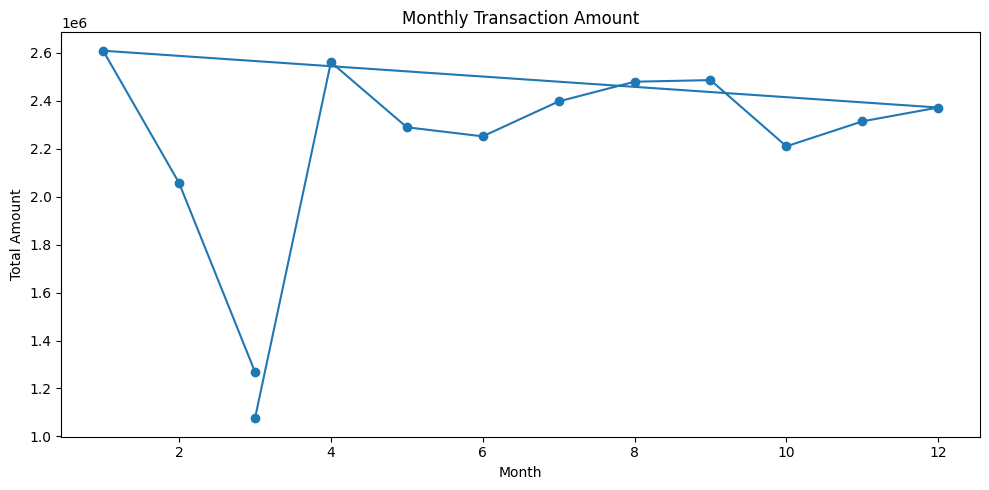

In [37]:
monthly_amount = df_clean.groupby(["year", "month_num"], as_index=False)["amount"].sum()

plt.figure(figsize=(10, 5))
plt.plot(monthly_amount["month_num"], monthly_amount["amount"], marker="o")
plt.title("Monthly Transaction Amount")
plt.xlabel("Month")
plt.ylabel("Total Amount")
plt.tight_layout()
plt.show()

### Question 36
Create a bar chart for total amount by city.

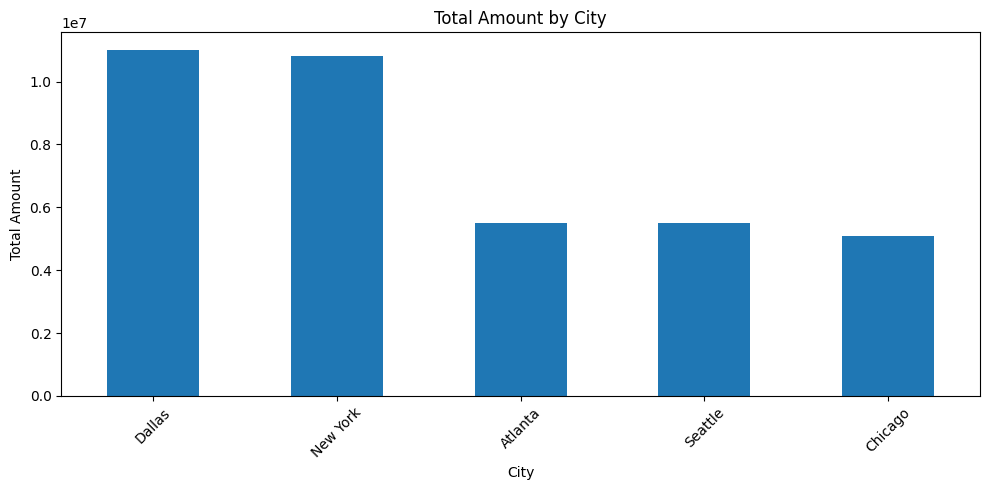

In [38]:
city_amount = df_clean.groupby("city")["amount"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
city_amount.plot(kind="bar")
plt.title("Total Amount by City")
plt.xlabel("City")
plt.ylabel("Total Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Question 37
Create a pie chart for account type contribution by amount.

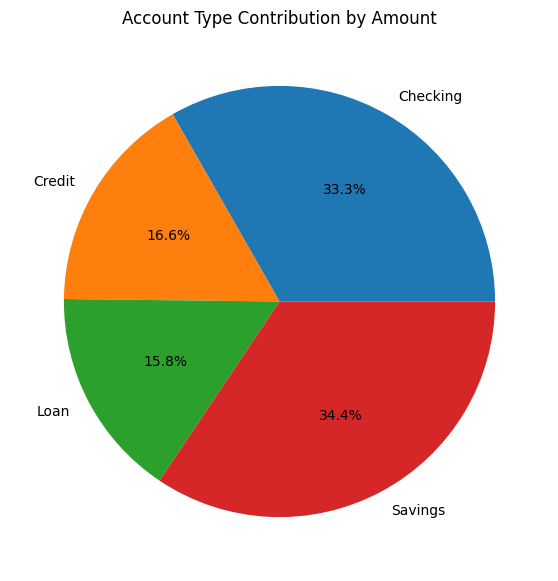

In [39]:
account_amount = df_clean.groupby("account_type")["amount"].sum()

plt.figure(figsize=(7, 7))
plt.pie(account_amount, labels=account_amount.index, autopct="%1.1f%%")
plt.title("Account Type Contribution by Amount")
plt.show()

---
**Note:** Questions 29, 33, and 34 were not captured in the source screenshots used to reconstruct this notebook and may be added later.